In [1]:
import arviz as az
import bambi as bmb
import polars as  pl
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

from kidney.contrasts import get_t_groups, get_overall_effects, get_gtyp_given_sex_age, get_sex_given_gtyp_age, get_mean
from kidney.paths import RESULTS_DIR_NEW, PREPARED_FILES_NEW, PLOT_DIR_NEW
from kidney.plotting import forestplot_oz, plot_ppc, set_symmetric_xlim
from kidney.sign_probs import get_sign_probs, get_signif

In [2]:
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'Arial'
az.rcParams["data.load"] = "eager"

In [3]:
idata_vehicle = az.from_netcdf(RESULTS_DIR_NEW / "idata_power_change_vehicle_single.nc")
idata_empa = az.from_netcdf(RESULTS_DIR_NEW / "idata_power_change_empa_single.nc")

In [4]:
print("Vehicle:")
display(az.summary(idata_vehicle, var_names=["~mu", "~1|rat", "~sigma"]))
print("Empa:")
display(az.summary(idata_empa, var_names=["~mu", "~1|rat", "~sigma"]))

Vehicle:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,-0.376,0.253,-0.833,0.101,0.006,0.005,1541.0,2042.0,1.0
gtyp[fa/fa],0.266,0.364,-0.457,0.924,0.009,0.008,1633.0,2101.0,1.0
age[Young],0.038,0.349,-0.624,0.685,0.008,0.007,1794.0,2041.0,1.0
sex[M],0.088,0.334,-0.518,0.732,0.008,0.007,1739.0,2041.0,1.0
"gtyp:age[fa/fa, Young]",-0.085,0.477,-1.022,0.795,0.011,0.009,1808.0,2086.0,1.0
"gtyp:sex[fa/fa, M]",-0.321,0.487,-1.179,0.618,0.012,0.011,1580.0,1677.0,1.0
1|rat_sigma,0.642,0.105,0.452,0.835,0.003,0.002,985.0,1900.0,1.0


Empa:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,-0.923,0.351,-1.565,-0.279,0.009,0.008,1466.0,1682.0,1.0
gtyp[fa/fa],0.532,0.500,-0.408,1.465,0.012,0.009,1608.0,2062.0,1.0
age[Young],0.345,0.487,-0.585,1.255,0.014,0.010,1246.0,2069.0,1.0
sex[M],-0.980,0.473,-1.852,-0.133,0.012,0.009,1561.0,2077.0,1.0
"gtyp:age[fa/fa, Young]",-0.815,0.688,-2.076,0.448,0.017,0.013,1584.0,2220.0,1.0
"gtyp:sex[fa/fa, M]",0.815,0.670,-0.523,1.990,0.016,0.014,1660.0,1910.0,1.0
1|rat_sigma,0.884,0.138,0.644,1.142,0.004,0.003,1319.0,2377.0,1.0


In [5]:
msts_vehicle = pl.read_csv(PREPARED_FILES_NEW["power_change_vehicle_single"])
msts_empa = pl.read_csv(PREPARED_FILES_NEW["power_change_empa_single"])

## Posterior predictive checks

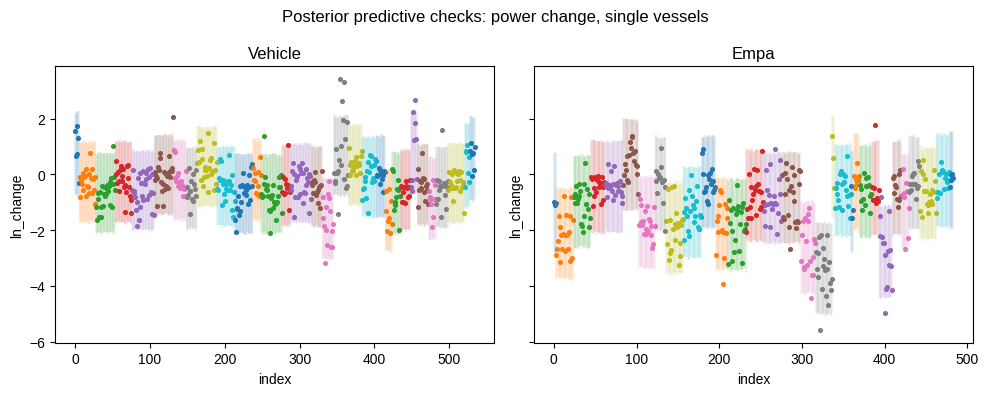

In [6]:
PLOT_DIR_NEW.mkdir(parents=True, exist_ok=True)
f, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, idata, name, msts in zip(
    axes,
    (idata_vehicle, idata_empa),
    ("vehicle", "empa"),
    (msts_vehicle, msts_empa),
):
    ax = plot_ppc(ax, idata, msts, ycol="ln_change", groupcol="rat")
    ax.set_title(name.capitalize())
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

f.suptitle("Posterior predictive checks: power change, single vessels")
f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ppc_power_change-single.png", bbox_inches="tight", dpi=200)

Each dot is a vessel, sorted by rat; lines are 1%–99% posterior predictive intervals. The dataset now contains only single vessels, so there is no activity-type-specific subdivision.

## Effects

The model is `ln_change ~ (1|rat) + gtyp + age + sex + gtyp:age + gtyp:sex`, with a single residual standard deviation. Contrasts follow the brief. The overall effect of a factor is averaged with equal weights over the levels of the other factors, e.g. the overall gtyp effect is the mean of fa/fa − fa/+ over the four age/sex groups. The gtyp effect given sex is averaged over age, and vice versa. SP is the posterior probability that the contrast is positive; lines are 95% intervals.
The combined plot replaces the overall sex effect with male − female contrasts within `fa/fa` and `fa/+`, averaged over age. Sex-given-age contrasts are excluded.

In [7]:
def plot_effects(ts_vehicle, ts_empa, figsize):
    f, axes = plt.subplots(1, 2, figsize=figsize)
    for ax, ts, tle in zip(axes, (ts_vehicle, ts_empa), ("Vehicle", "Empa")):
        ax = forestplot_oz(ax, ts, xlabel="Test statistic\n(power change)", sign_probs=True)
        set_symmetric_xlim(ax, ts, pad=1.8)
        ax.set_title(tle)
        ax.spines[['top', 'right', 'left']].set_visible(False)
    axes[1].set_yticks([], [])
    return f, axes


t_groups_vehicle, t_groups_empa = (get_t_groups(idata) for idata in (idata_vehicle, idata_empa))
overall_ts_vehicle, overall_ts_empa = (
    get_overall_effects(t_groups)
    for t_groups in (t_groups_vehicle, t_groups_empa)
)
gtyp_ts_vehicle, gtyp_ts_empa = (get_gtyp_given_sex_age(t_groups) for t_groups in (t_groups_vehicle, t_groups_empa))
sex_ts_vehicle, sex_ts_empa = (
    get_sex_given_gtyp_age(t_groups)
    for t_groups in (t_groups_vehicle, t_groups_empa)
)

# Replace the overall sex contrast with sex effects within each genotype.
# Exclude the sex-given-age contrasts.
plot_ts_vehicle = {
    **{k: v for k, v in overall_ts_vehicle.items() if k != "male - female"},
    **{k: v for k, v in sex_ts_vehicle.items() if k in ("male - female, fa/fa", "male - female, fa/+")},
}
plot_ts_empa = {
    **{k: v for k, v in overall_ts_empa.items() if k != "male - female"},
    **{k: v for k, v in sex_ts_empa.items() if k in ("male - female, fa/fa", "male - female, fa/+")},
}

### Overall genotype and age effects; sex effects given genotype

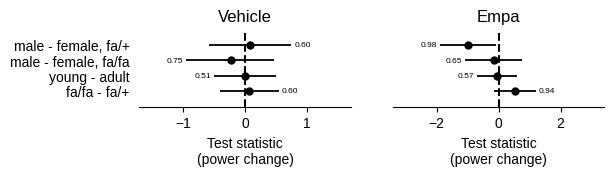

In [8]:
f, axes = plot_effects(plot_ts_vehicle, plot_ts_empa, figsize=(6, 1))
f.savefig(PLOT_DIR_NEW / "ts_power_change_overall_and_sg-single.pdf", bbox_inches="tight", dpi=200)

### Effect of gtyp given sex and given age

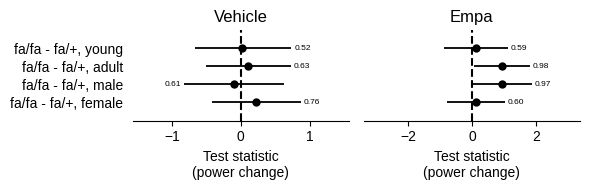

In [9]:
f, axes = plot_effects(gtyp_ts_vehicle, gtyp_ts_empa, figsize=(6, 2))
f.tight_layout()
# f.savefig(PLOT_DIR_NEW / "ts_power_change_gtyp_given_sex_age-single.png", bbox_inches="tight", dpi=200)

### Mean change

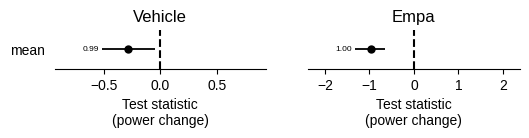

In [10]:
mean_ts_vehicle, mean_ts_empa = (
    {"mean": get_mean(idata)} for idata in (idata_vehicle, idata_empa)
)
f, axes = plot_effects(mean_ts_vehicle, mean_ts_empa, figsize=(6, 0.5))
f.savefig(PLOT_DIR_NEW / "ts_power_change_mean-single.pdf", bbox_inches="tight", dpi=200)

## Show sign probabilities in tables

In [11]:
sp_all = pd.concat(
    objs=[
        pd.DataFrame({
            "vehicle": get_sign_probs(ts_vehicle),
            "vehicle_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_vehicle).items()},
            "empa": get_sign_probs(ts_empa),
            "empa_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_empa).items()},
        })
        for ts_vehicle, ts_empa in (
            (plot_ts_vehicle, plot_ts_empa),
            (gtyp_ts_vehicle, gtyp_ts_empa),
            (mean_ts_vehicle, mean_ts_empa),
        )
    ],
    keys=("overall + sex given gtyp", "gtyp given sex/age", "mean"),
    names=("contrast", "group"),
)
sp_all

vehicle vehicle_signif  \
contrast                 group                                          
overall + sex given gtyp fa/fa - fa/+          0.60325                  
                         young - adult         0.51250                  
                         male - female, fa/fa  0.75275                  
                         male - female, fa/+   0.60500                  
gtyp given sex/age       fa/fa - fa/+, female  0.76025                  
                         fa/fa - fa/+, male    0.61050                  
                         fa/fa - fa/+, adult   0.63350                  
                         fa/fa - fa/+, young   0.51550                  
mean                     mean                  0.99000              *   

                                                  empa empa_signif  
contrast                 group                                      
overall + sex given gtyp fa/fa - fa/+          0.94350              
                         young - adult         0.57375              
                         male - female, fa/fa  0.65025              
                         male - female, fa/+   0.98275           *  
gtyp given sex/age       fa/fa - fa/+, female  0.60425              
                         fa/fa - fa/+, male    0.97100              
                         fa/fa - fa/+, adult   0.98175           *  
                         fa/fa - fa/+, young   0.59025              
mean                     mean                  1.00000           *